This notebook contains code to generate figures 1, 2, 3, 4, 5 in the paper.

In [30]:
from pathlib import Path
import sys
sys.path.append(str(Path('.').resolve().parent / 'src'))

In [31]:
from preprocessing import load_preprocessed_corpus

preprocessed_corpus_path = Path('.').resolve().parent / "output" / "preprocessed_conllu_corpus.json"
data = load_preprocessed_corpus(preprocessed_corpus_path, max_issues_per_date=10)

In [32]:
import numpy as np
from collections import defaultdict

# Reference decade distribution (absolute issue counts) to match.
ref = np.array(
    [174177, 243572, 306121, 307531, 133070,
     200329, 208536, 212615, 223314, 226992.]
)

by_decade = defaultdict(list)
for issue in data:
    by_decade[(issue['year'] // 10) * 10].append(issue)

decades = sorted(by_decade)
assert len(decades) == len(ref), 'decade count does not match reference'

available = np.array([len(by_decade[d]) for d in decades], dtype=float)
ref_frac = ref / ref.sum()

scale = min(available[i] / ref_frac[i] for i in range(len(decades)))
targets = np.floor(scale * ref_frac).astype(int)

rng = np.random.default_rng(0)
downsampled = []
for d, n in zip(decades, targets):
    pool = by_decade[d]
    idx = rng.choice(len(pool), size=n, replace=False)
    downsampled.extend(pool[i] for i in idx)

data = downsampled
len(data)

32375

In [33]:
from orthography_change.rules.loader import (
    load_rules_by_old_form, load_rules_by_new_form,
)
from config import RULES_FILE, AGGREGATION_MONTHS
from orthography_change.analyzer import OrthographyAnalyzer
from orthography_change.statistics import Statistics
from orthography_change.adoption import AdoptionCalculator

old_index = load_rules_by_old_form(RULES_FILE)
new_index = load_rules_by_new_form(RULES_FILE)
analyzer = OrthographyAnalyzer(old_index, new_index)
results = [analyzer.analyze_from_cache(issue) for issue in data]

stat = Statistics()
df_combined = stat.aggregate_by_period(results, months=AGGREGATION_MONTHS)
df = df_combined

calc = AdoptionCalculator()

Aggregating: 100%|██████████| 32375/32375 [00:00<00:00, 65048.89it/s]


In [34]:
import config
from language_classification import attach_labels, load_classified_corpus

classified_issues = load_classified_corpus(config.CLASSIFIED_CACHE)
attach_labels(results, classified_issues)

bokmaal_labels = config.LANGUAGE_LABEL_GROUPS["bokmaal_dan"]
nynorsk_labels = config.LANGUAGE_LABEL_GROUPS["nynorsk"]

df_bokmaal = stat.aggregate_by_period(
    [r for r in results if r["label"] in bokmaal_labels],
    months=AGGREGATION_MONTHS,
)
df_nynorsk = stat.aggregate_by_period(
    [r for r in results if r["label"] in nynorsk_labels],
    months=AGGREGATION_MONTHS,
)

len(df_bokmaal), len(df_nynorsk)

Aggregating: 100%|██████████| 1485/1485 [00:00<00:00, 54451.48it/s]


(200, 179)

## Figure 5

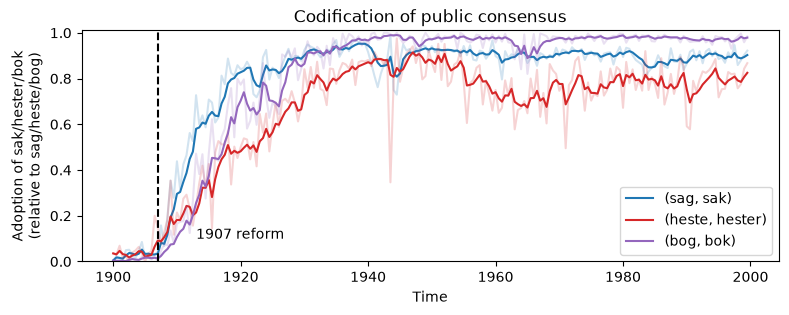

In [35]:
import matplotlib.pyplot as plt

ewma_span = 5

curve_1 = calc.compute_curve(df, old_form="sag", new_form="sak", use_ewma=False)
curve_2 = calc.compute_curve(df, old_form="heste", new_form="hester", use_ewma=False)
curve_3 = calc.compute_curve(df, old_form="bog", new_form="bok", use_ewma=False)
ewma_1 = calc.compute_curve(df, old_form="sag", new_form="sak", use_ewma=True, ewma_span=ewma_span)
ewma_2 = calc.compute_curve(df, old_form="heste", new_form="hester", use_ewma=True, ewma_span=ewma_span)
ewma_3 = calc.compute_curve(df, old_form="bog", new_form="bok", use_ewma=True, ewma_span=ewma_span)

fig, ax = plt.subplots(figsize=(9, 3))
raw_alpha = 0.2


ax.plot(curve_1['period'], curve_1['adoption'], alpha=raw_alpha, c='tab:blue');
ax.plot(ewma_1['period'], ewma_1['adoption'], label='(sag, sak)', c='tab:blue');

ax.plot(curve_2['period'], curve_2['adoption'], alpha=raw_alpha, c='tab:red');
ax.plot(ewma_2['period'], ewma_2['adoption'], label='(heste, hester)', c='tab:red');

ax.plot(curve_3['period'], curve_3['adoption'], alpha=raw_alpha, c='tab:purple')
ax.plot(ewma_3['period'], ewma_3['adoption'],
        label='(bog, bok)', c='tab:purple')

delta = 4
ax.text(1909 + delta, 0.085, "1907 reform", va='bottom', ha='left')
# ax.text(1925 + delta, 0.0, "Breakaway from Danish orthography\nUniversally spoken consensus\nBetter grammatical efficiency", va='bottom', ha='left')
ax.axvline(1907, c='k', linestyle='dashed')

ax.set_title('Codification of public consensus')
ax.set_ylabel('Adoption of sak/hester/bok\n(relative to sag/heste/bog)')
ax.set_xlabel('Time')
ax.legend()
ax.set_ylim(0, 1.01)

fig.savefig('solidifying-consensus-adoption.pdf', bbox_inches='tight', dpi=600)

plt.show()

## Figure 4

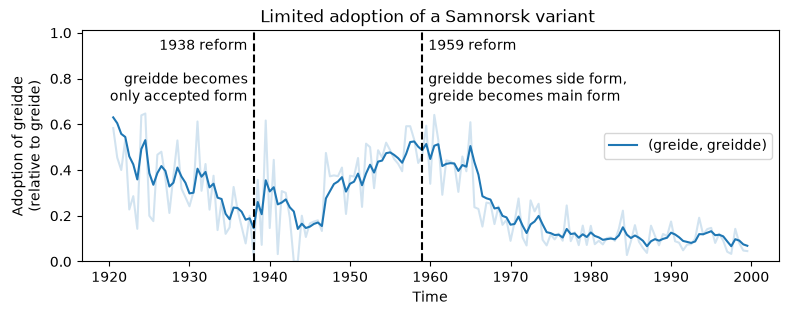

In [58]:
import matplotlib.pyplot as plt

ewma_span = 5

curve_1 = calc.compute_curve(df, old_form="greide", new_form="greidde", use_ewma=False)
ewma_1 = calc.compute_curve(df, old_form="greide", new_form="greidde", use_ewma=True, ewma_span=ewma_span)

fig, ax = plt.subplots(figsize=(9, 3))
raw_alpha = 0.2

curve_1 = curve_1[curve_1['period'] > 1920]
ewma_1 = ewma_1[ewma_1['period'] > 1920]

ax.plot(curve_1['period'], curve_1['adoption'], alpha=raw_alpha, c='tab:blue');
ax.plot(ewma_1['period'], ewma_1['adoption'], label='(greide, greidde)', c='tab:blue');

ax.text(1938 - 0.75, 0.98, '1938 reform\n\ngreidde becomes\nonly accepted form', ha='right', va='top')
ax.text(1959 + 0.75, 0.98, '1959 reform\n\ngreidde becomes side form,\ngreide becomes main form', ha='left', va='top')
ax.axvline(1938, c='k', linestyle='dashed')
ax.axvline(1959, c='k', linestyle='dashed')

# ax.set_title('Failed top-down enforcement; subsequent reversal and resurgence')
ax.set_title('Limited adoption of a Samnorsk variant ')
ax.set_ylabel('Adoption of greidde\n(relative to greide)')
ax.set_xlabel('Time')
ax.legend()
ax.set_ylim(0, 1.01)

fig.savefig('resurgence-adoption.pdf', bbox_inches='tight', dpi=600)

plt.show()

## Figure 3

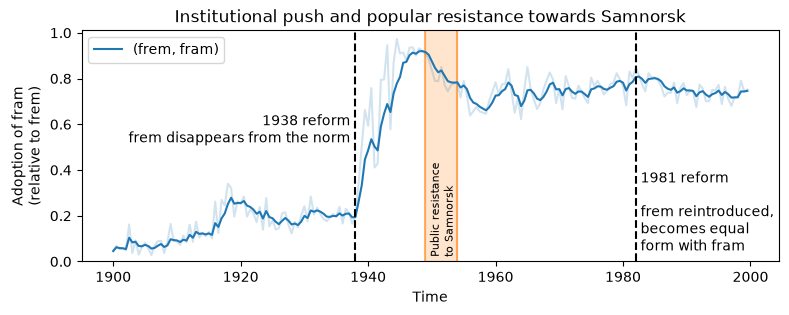

In [56]:
import matplotlib.pyplot as plt

ewma_span = 5

curve_1 = calc.compute_curve(df, old_form="frem", new_form="fram", use_ewma=False)
ewma_1 = calc.compute_curve(df, old_form="frem", new_form="fram", use_ewma=True, ewma_span=ewma_span)

fig, ax = plt.subplots(figsize=(9, 3))
raw_alpha = 0.2

ax.plot(curve_1['period'], curve_1['adoption'], alpha=raw_alpha, c='tab:blue');
ax.plot(ewma_1['period'], ewma_1['adoption'], label='(frem, fram)', c='tab:blue');

ax.axvline(1938, c='k', linestyle='dashed')
ax.text(1938 - 0.75, 0.65, '1938 reform\nfrem disappears from the norm', ha='right', va='top')

ax.axvline(1982, c='k', linestyle='dashed')
ax.text(1982 + 0.75, 0.4, '1981 reform\n\nfrem reintroduced,\nbecomes equal\nform with fram', ha='left', va='top')

ax.axvline(1949, c='tab:orange', alpha=0.6, zorder=-1)
ax.axvline(1954, c='tab:orange', alpha=0.6, zorder=-1)
ax.fill_between([1949, 1954], 0, 1.2, alpha=0.2, color='tab:orange')
ax.text(1953 - 3.5, 0.02, 'Public resistance\nto Samnorsk', ha='left', va='bottom', rotation=90, fontsize=8)

ax.set_title('Institutional push and popular resistance towards Samnorsk')
ax.set_ylabel('Adoption of fram\n(relative to frem)')
ax.set_xlabel('Time')
ax.legend(loc='upper left')
ax.set_ylim(0, 1.01)

fig.savefig('multiple-contested-adoption.pdf', bbox_inches='tight', dpi=600)

plt.show()

In [38]:
import pandas as pd

rules_df = pd.read_csv(RULES_FILE)

convergence_pairs = []
for new_form, group in rules_df.groupby("new_form"):
    languages = set(group["language"])
    if not {"nb", "nn"}.issubset(languages):
        continue
    nb_old_form = group.loc[group["language"] == "nb", "old_form"].iloc[0]
    nn_old_form = group.loc[group["language"] == "nn", "old_form"].iloc[0]
    convergence_pairs.append((new_form, nb_old_form, nn_old_form))

convergence_pairs

[('dråpe', 'draabe', 'drope'), ('mellom', 'mellem', 'millom')]

## Figure 2

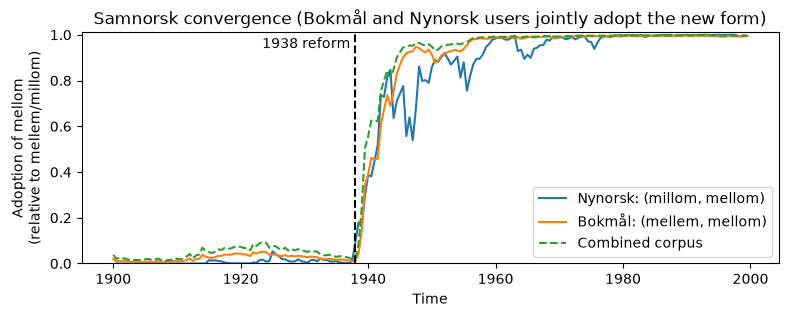

In [61]:
new_form, nb_old_form, nn_old_form = ('mellom', 'mellem', 'millom')

nn_curve = calc.compute_curve(
    df_nynorsk,
    old_form=nn_old_form,
    new_form=new_form,
    use_ewma=True,
)
nb_curve = calc.compute_curve(
    df_bokmaal,
    old_form=nb_old_form,
    new_form=new_form,
    use_ewma=True,
)
combined_nb_curve = calc.compute_curve(
    df_combined,
    old_form=nb_old_form,
    new_form=new_form,
    use_ewma=False,
)
combined_nn_curve = calc.compute_curve(
    df_combined,
    old_form=nn_old_form,
    new_form=new_form,
    use_ewma=False,
)
combined_curve = calc.compute_meta_curve(
    [combined_nb_curve, combined_nn_curve],
    use_ewma=True,
)

fig, ax = plt.subplots(figsize=(9, 3))

ax.plot(
    nn_curve['period'],
    nn_curve['adoption'],
    label=f'Nynorsk: ({nn_old_form}, {new_form})',
    c='tab:blue',
)
ax.plot(
    nb_curve['period'],
    nb_curve['adoption'],
    label=f'Bokmål: ({nb_old_form}, {new_form})',
    c='tab:orange',
)
ax.plot(
    combined_curve['period'],
    combined_curve['adoption'],
    label='Combined corpus', c='tab:green', linestyle='dashed',
)
ax.axvline(1938, c='k', linestyle='dashed')
ax.text(1938 - 0.75, 0.99, '1938 reform', ha='right', va='top')

ax.set_title(
    f'Samnorsk convergence (Bokmål and Nynorsk users jointly adopt the new form)')
ax.set_ylabel('Adoption of mellom\n(relative to mellem/millom)')
ax.set_xlabel('Time')
ax.legend(loc='lower right')
ax.set_ylim(0, 1.01)

fig.savefig(
    f'samnorsk-convergence-{new_form}.pdf',
    bbox_inches='tight', dpi=600,
)

plt.show()

# Time-to-adoption computation

In [11]:
import pandas as pd

_forms = pd.read_csv(Path('.').resolve().parent / "data" / "rules.csv")
_forms = _forms[(_forms['status_before'] == 'main_form') &
                (_forms['status_after'] == 'main_form')]
_forms = _forms[['effective_year', 'language', 'old_form', 'new_form']]
_forms = _forms.rename({'effective_year': 'reform_year'}, axis=1)

In [12]:
# Pairs never observed after their reform have undefined adoption. They are
# missing data, not censored at the corpus end, so they are dropped.
curves = dict()
for index, row in _forms.iterrows():
    curve = calc.compute_curve(
        df,
        old_form=row['old_form'],
        new_form=row['new_form'],
        ewma_span=20,
        use_ewma=True
    )
    _post = curve[curve['period'] >= row['reform_year']]
    if _post['adoption'].notna().any():
        curves[index] = curve
    else:
        print(f"Dropped ({row['reform_year']}): "
              f"{row['old_form']} -> {row['new_form']}")
_forms = _forms.loc[list(curves)].copy()

Dropped (1901): visorna -> visorne
Dropped (1917): ei visa -> ei vise


In [13]:
import numpy as np


def _tta_pair(pair: pd.DataFrame, start_year: float, threshold: float):
    """Compute time-to-adoption for a word pair (accounts for censoring).

    Args:
        pair (pd.DataFrame): Adoption curve with columns
            'period' and 'adoption'.
        start_year (float): Reform year to measure time from.
        threshold (float): Adoption level defining the event.

    Returns:
        tuple[float, bool]: Time to adoption in years, and whether adoption was 
            observed.
    """
    _subset = pair[pair['period'] >= start_year]
    if _subset.empty:
        return np.nan, False
    for _, row in _subset.iterrows():
        if row['adoption'] >= threshold:
            return row['period'] - start_year, True
    return _subset['period'].max() - start_year, False


TARGETS = list(range(0, 100, 1))
for target in TARGETS:
    _tta = [_tta_pair(
        val, start_year=_forms.loc[key, 'reform_year'],
        threshold=target / 100
    ) for key, val in curves.items()]
    _forms[f'tta_{target}'] = [t for t, _ in _tta]
    _forms[f'tta_{target}_event'] = [e for _, e in _tta]

C:\Users\david\AppData\Local\Temp\ipykernel_15072\3374584089.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  _forms[f'tta_{target}_event'] = [e for _, e in _tta]
C:\Users\david\AppData\Local\Temp\ipykernel_15072\3374584089.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  _forms[f'tta_{target}'] = [t for t, _ in _tta]


In [14]:
def _kaplan_meier_rmst(times: np.ndarray, events: np.ndarray, tau: float):
    """Restricted mean survival time via Kaplan-Meier.

    Args:
        times (np.ndarray): Event/censoring times with shape (n,).
        events (np.ndarray): True where the adoption target was
            observed to be reached. Has shape (n,).
        tau (float): Restriction horizon for the integral.

    Returns:
        float: Restricted mean survival time up to tau.
    """
    order = np.argsort(times)
    t, e = times[order], events[order]
    surv, prev_t, rmst = 1.0, 0.0, 0.0
    for ut in np.unique(t[t <= tau]):
        rmst += surv * (ut - prev_t)
        at_risk = np.sum(t >= ut)
        deaths = np.sum((t == ut) & e)
        surv *= (1 - deaths / at_risk)
        prev_t = ut
    rmst += surv * (tau - prev_t)
    return rmst


def _bootstrap_rmst(times: np.ndarray,
                    events: np.ndarray,
                    tau: float,
                    n_boot: int = 2000,
                    ci: float = 0.95,
                    seed: int = 0):
    """Bootstrap CI for the Kaplan-Meier RMST.

    Args:
        times (np.ndarray): Adoption/censoring times with shape (n,).
        events (np.ndarray): Adoption flags with shape (n,).
        tau (float): Restriction horizon, fixed across resamples.
        n_boot (int): Number of bootstrap resamples.
        ci (float): Confidence level, e.g. 0.95 for a 95% CI.
        seed (int): RNG seed for reproducibility.

    Returns:
        tuple[float, float]: Lower and upper CI bounds.
    """
    rng = np.random.default_rng(seed)
    n = len(times)
    if n < 2:
        return np.nan, np.nan
    idx = rng.integers(0, n, size=(n_boot, n))
    boot = [_kaplan_meier_rmst(times[i], events[i], tau) for i in idx]
    alpha = (1 - ci) / 2
    lo, hi = np.nanpercentile(boot, [100 * alpha, 100 * (1 - alpha)])
    return float(lo), float(hi)


res_list = []
for target in TARGETS:
    print(f'{target=}')
    rows = []
    for ry, sub in _forms.groupby('reform_year'):
        times = sub[f'tta_{target}'].to_numpy(dtype=float)
        events = sub[f'tta_{target}_event'].to_numpy(dtype=bool)
        mask = ~np.isnan(times)
        times, events = times[mask], events[mask]
        if len(times) == 0:
            rows.append((ry, np.nan, np.nan, np.nan))
            continue
        tau = times.max()
        rmst = _kaplan_meier_rmst(times, events, tau)
        lo, hi = _bootstrap_rmst(times, events, tau, ci=0.75)
        rows.append((ry, rmst, lo, hi))
    tmp = pd.DataFrame(
        rows, columns=['reform_year', 'tta', 'ci_lower', 'ci_upper']
    )
    tmp['target'] = target
    res_list.append(tmp)

target=0


target=1


target=2


target=3


target=4


target=5


... (90 outputs left out)

target=96


target=97


target=98


target=99


## Figure 1

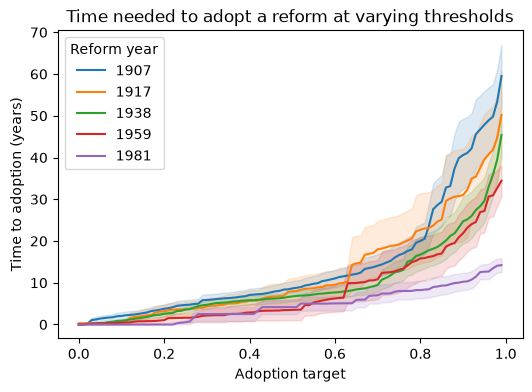

In [15]:
tmp = pd.concat(res_list, axis=0, ignore_index=True)
fig, ax = plt.subplots(figsize=(6, 4))
for ry in tmp['reform_year'].unique():
    if ry != 1901:
        ss = tmp[tmp['reform_year'] == ry]
        if ry == 1982:
            ry = 1981
        line, = ax.plot(ss['target'] / 100, ss['tta'], label=f'{int(ry)}')
        ax.fill_between(ss['target'] / 100, ss['ci_lower'], ss['ci_upper'],
                        color=line.get_color(), alpha=0.15)
ax.legend(title='Reform year')
ax.set_xlabel('Adoption target')
ax.set_ylabel('Time to adoption (years)')
ax.set_title('Time needed to adopt a reform at varying thresholds')
fig.savefig('time-to-adoption.pdf', bbox_inches='tight', dpi=600)
plt.show()

In [18]:
print(tmp[tmp['target'] == 90][['reform_year', 'tta']].reset_index(drop=True))

   reform_year        tta
0         1901   2.000000
1         1907  40.590909
2         1917  31.000000
3         1938  24.714286
4         1959  21.846154
5         1982  10.238095
